# Explorer un jeu d'images avant d'entrainer

Trois questions, sans etiquette ni entrainement :
1. le jeu est-il sain ? (fichiers, tailles, doublons, fuites entre sous-ensembles, raccourcis)
2. a quoi ressemble-t-il ? (plongements d'un reseau pre-entraine, projection 2D, groupes)
3. les images d'aujourd'hui ressemblent-elles a celles de l'entrainement ? (derive)

In [1]:
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import pandas as pd  # pandas : tableaux de donnees (relit les CSV produits)
from IPython.display import Image, Markdown, display  # affiche dans le notebook une image ou un texte Markdown du disque

from vtb.core.config import load_config  # lit le fichier YAML de l'experience et verifie chaque reglage
from vtb.core.experiment import start  # prepare l'experience : dossier de sortie, journal, graines, choix CPU / GPU
from vtb.explore import workflow  # les traitements d'exploration (controle du jeu, plongements, derive)
from vtb.explore.config import DriftConfig, ExploreConfig  # modeles de configuration (derive ; exploration)

config = load_config("recipes/explore/configs/neu_cls.yaml", ExploreConfig)  # config d'exploration du jeu NEU-CLS
# meme config, mais les sorties vont dans un dossier a part pour ne pas melanger avec celles des scripts
config = config.model_copy(update={"runtime": config.runtime.model_copy(update={"output_dir": "outputs/explore/notebook"})})
output, device = start(config, "notebook")  # cree le dossier de sortie, le journal, fixe les graines ; device = CPU ou GPU

2026-11-05 19:21:23,456 | INFO | notebook | sortie outputs/explore/notebook | device cpu


## 1. Controle du jeu

Les alertes en premier : fichiers illisibles, types melanges, doublons a cheval sur deux
sous-ensembles (le test serait truque), doublons a deux etiquettes (erreurs d'annotation),
statistique simple qui predit la classe (le modele apprendrait l'acquisition, pas le defaut).

2026-11-05 19:21:23,501 | INFO | catalogue : 1800 images | layout class_folders | 1800 groupes


2026-11-05 19:21:25,699 | INFO | doublons : 9724 candidats dHash, 2 confirmes


2026-11-05 19:21:28,349 | INFO | alerte : 1 doublon(s) a cheval sur deux sous-ensembles : FUITE, decouper par groupe


2026-11-05 19:21:28,350 | INFO | alerte : 47 image(s) atypique(s) a regarder (voir outliers.csv)


# Controle du jeu : data/raw/neu_cls_flat

## Alertes

- 1 doublon(s) a cheval sur deux sous-ensembles : FUITE, decouper par groupe
- 47 image(s) atypique(s) a regarder (voir outliers.csv)

## Chiffres

- images : 1800 (lisibles : 1800)
- classes : {'crazing': 300, 'inclusion': 300, 'patches': 300, 'pitted': 300, 'rolled': 300, 'scratches': 300}
- tailles les plus frequentes : {'200x200': 1800}
- paires de doublons : 2 (exacts : 1)

## Raccourcis possibles (une statistique seule predit-elle la classe ?)

| statistic          |   balanced_accuracy |   chance |
|:-------------------|--------------------:|---------:|
| sharpness          |               0.585 |    0.167 |
| std                |               0.506 |    0.167 |
| mean               |               0.404 |    0.167 |
| saturated_fraction |               0.352 |    0.167 |
| dark_fraction      |               0.224 |    0.167 |


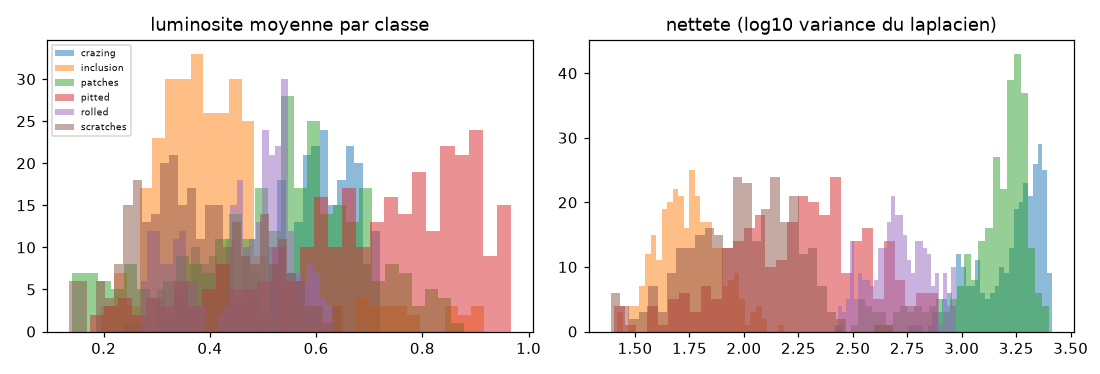

In [2]:
summary = workflow.check_dataset(config, output)  # controle complet du jeu ; renvoie un resume et ecrit le rapport
display(Markdown((output / "quality_report.md").read_text()))  # affiche le rapport Markdown (alertes en tete)
display(Image(str(output / "stats_by_class.png"), width=640))  # statistiques simples des images (luminosite...) par classe

## 2. Plongements : la structure du jeu sans etiquette

Un vecteur par image (resnet18 ImageNet sans sa tete). Si les classes forment des groupes
separes, un modele simple suffira ; un groupe inattendu signale souvent deux acquisitions.

2026-11-05 19:21:28,391 | INFO | catalogue : 1800 images | layout class_folders | 1800 groupes


2026-11-05 19:24:42,843 | INFO | 1800 plongements de dimension 512


2026-11-05 19:25:14,820 | INFO | plongements : {'n_images': 1800, 'dimension': 512, 'n_clusters': 6, 'cluster_purity': 0.913}


{'n_images': 1800, 'dimension': 512, 'n_clusters': 6, 'cluster_purity': 0.913}


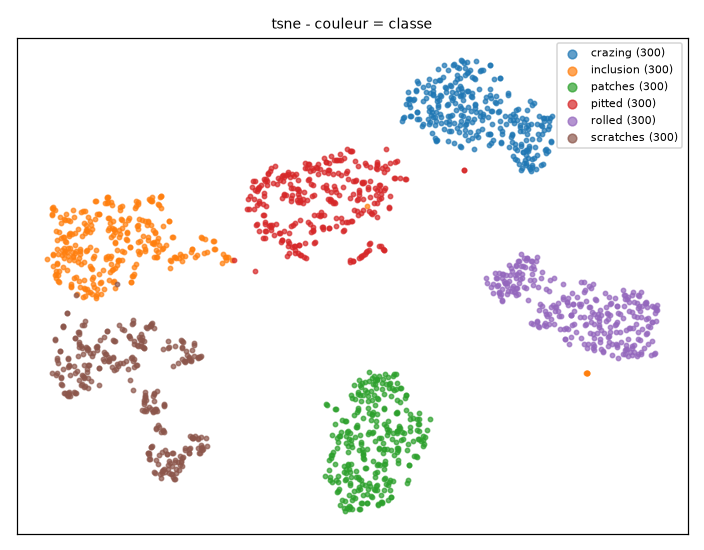

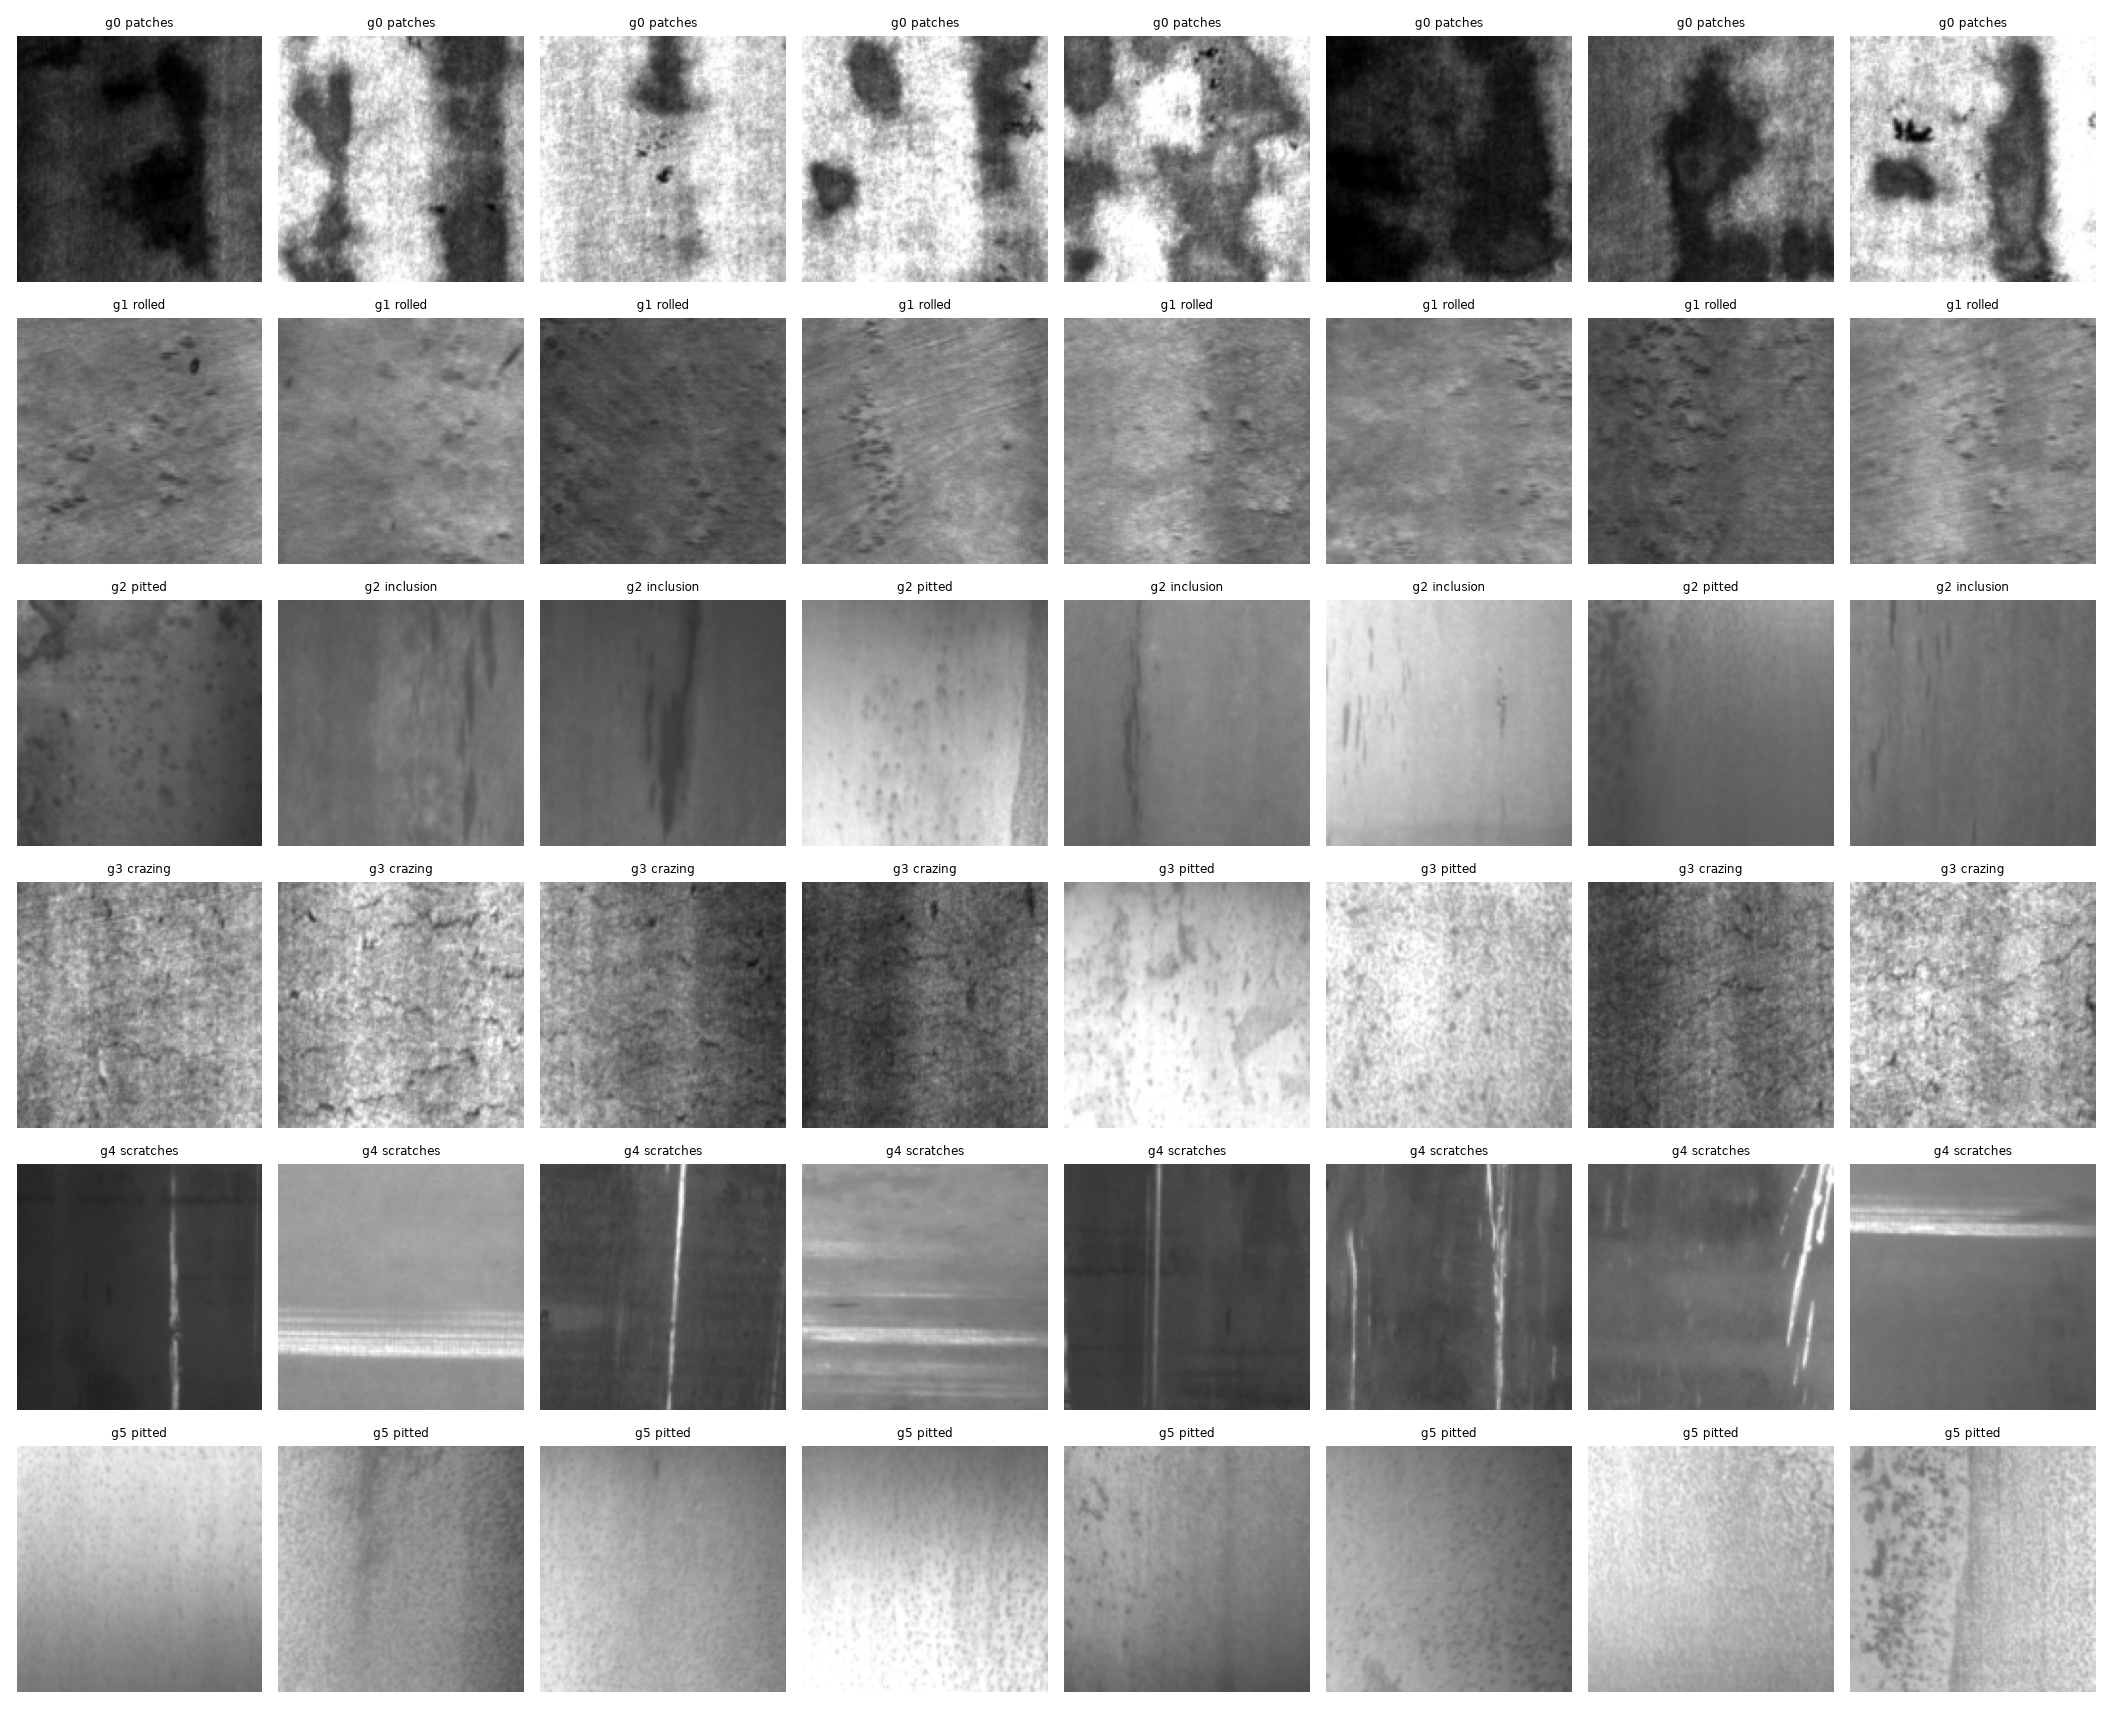

In [3]:
# plongement = vecteur qui resume une image ; calcule ceux de tout le jeu, la projection 2D et les groupes (k-means)
result = workflow.embeddings(config, output, device)
print({k: v for k, v in result.items() if k != "neighbours_example"})  # resume, sans l'exemple de voisins (trop long)
display(Image(str(output / "projection_by_label.png"), width=480))  # nuage de points 2D, une couleur par classe
display(Image(str(output / "clusters_gallery.png"), width=900))  # quelques images de chaque groupe trouve

## 3. Derive : reference contre courant

Un classifieur essaie de distinguer les deux periodes ; AUC ~ 0,5 = indiscernables. Ici la
derive est SIMULEE (images assombries et floutees) pour montrer ce que l'on obtient.

2026-11-05 19:25:14,963 | INFO | catalogue : 1770 images | layout flat | 1770 groupes


2026-11-05 19:25:14,971 | INFO | catalogue : 30 images | layout flat | 30 groupes


2026-11-05 19:25:49,372 | INFO | 300 plongements de dimension 512


2026-11-05 19:25:51,968 | INFO | 30 plongements de dimension 512


2026-11-05 19:25:53,292 | INFO | derive : AUC 0.422 -> pas de derive detectable


2026-11-05 19:25:53,330 | INFO | catalogue : 1770 images | layout flat | 1770 groupes


... (3 outputs left out)

2026-11-05 19:26:27,595 | INFO | 300 plongements de dimension 512


2026-11-05 19:26:40,939 | INFO | 150 plongements de dimension 512


2026-11-05 19:26:42,084 | INFO | derive : AUC 0.999 -> derive forte : reevaluer le modele avant de lui faire confiance


drift_simulated | AUC 0.999 | derive forte : reevaluer le modele avant de lui faire confiance
         statistic   ks      p_value  reference_median  current_median
         sharpness 0.70 1.507799e-47          377.8203         12.9690
saturated_fraction 0.33 4.442898e-10            0.0000          0.0000
              mean 0.26 2.230215e-06            0.4696          0.3543


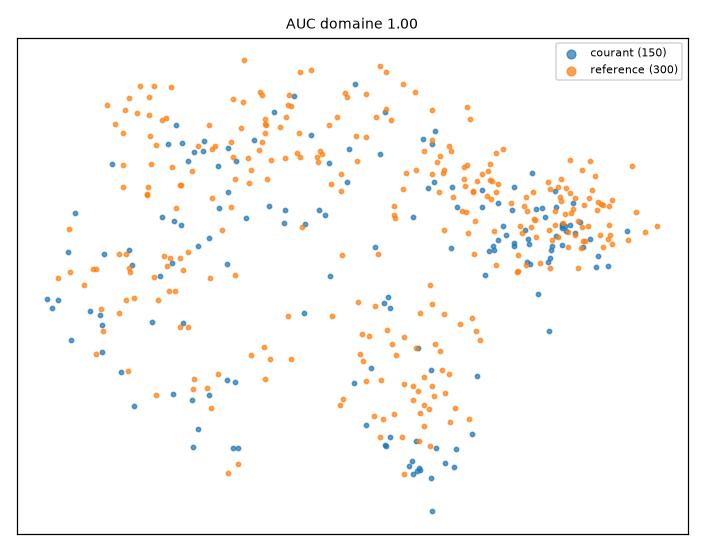

In [4]:
for name in ("drift_none", "drift_simulated"):  # deux cas : sans derive, puis avec une derive simulee
    drift_config = load_config(f"recipes/explore/configs/{name}.yaml", DriftConfig)  # config de ce cas
    drift_output = Path(drift_config.runtime.output_dir)  # dossier de sortie de ce cas
    drift_output.mkdir(parents=True, exist_ok=True)  # le cree s'il n'existe pas
    report = workflow.drift(drift_config, drift_output, device)  # mesure la derive ; renvoie un resume (AUC, verdict...)
    # AUC du classifieur reference / courant : ~0,5 = pas de derive, proche de 1 = les images ont change
    print(name, "| AUC", report["domain_auc"], "|", report["verdict"])
    print(pd.read_csv(drift_output / "statistics_drift.csv").head(3).to_string(index=False))  # les 3 statistiques qui bougent le plus
display(Image(str(drift_output / "drift_projection.png"), width=420))  # projection 2D du dernier cas (derive simulee)